SESI 1 — PENDAHULUAN DAN PERSIAPAN

Studi kasus:
Pemantauan indikasi perubahan tutupan vegetasi di kawasan
tropis Kalimantan Tengah menggunakan citra satelit Sentinel-2.

Tujuan:
1. Mengakses data satelit asli, bukan data dummy.
2. Menghitung NDVI untuk mengamati kondisi vegetasi.
3. Membandingkan vegetasi pada dua periode.
4. Memetakan indikasi penurunan nilai NDVI.
5. Membahas kaitan AI serta keterbatasan hasil analisis.

Catatan:
Penurunan NDVI merupakan indikasi perubahan vegetasi,
bukan bukti pasti deforestasi atau penyebabnya.


SESI 2 — PENGAMBILAN DATA SATELIT
Wilayah studi: Kalimantan Tengah
Proyeksi: EPSG:32749
Resolusi: 20 meter
Ukuran grid: 1110 x 1116 piksel

SESI 3 — PENGOLAHAN CITRA DAN NDVI

Tahun target       : 2023
ID citra           : S2A_MSIL2A_20230902T022541_R046_T49MHT_20240916T130436
Tanggal citra      : 2023-09-02
Tutupan awan scene : 0.131557 %

Tahun target       : 2025
ID citra           : S2C_MSIL2A_20250504T022611_R046_T49MGT_20250504T074915
Tanggal citra 

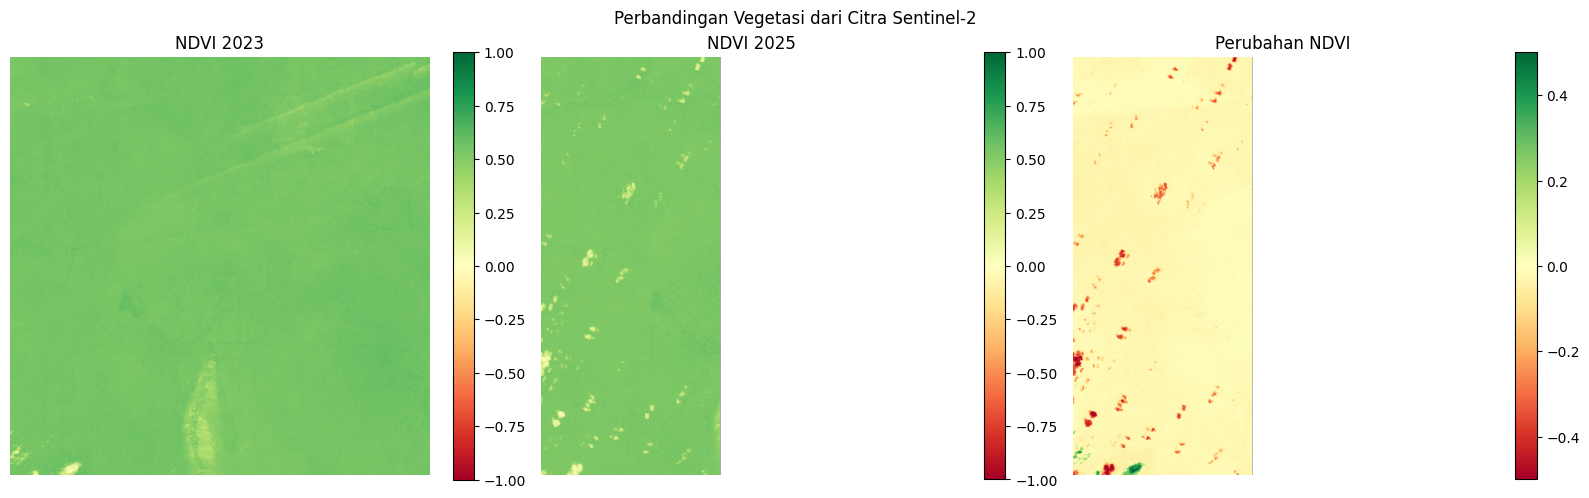

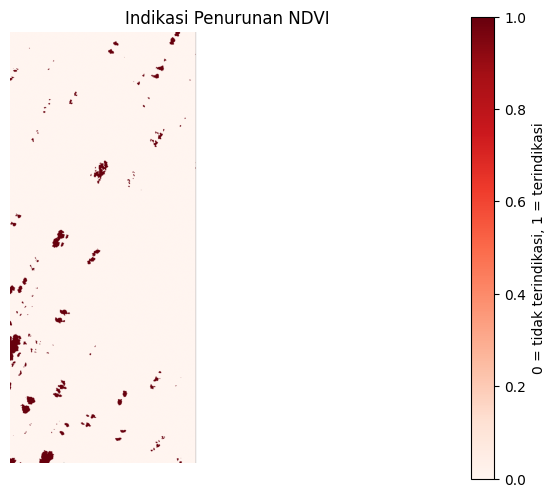


SESI 6 — AI DAN MACHINE LEARNING

Materi webinar membahas CNN untuk mengklasifikasikan penyebab
perubahan hutan, misalnya:
- Pertanian
- Pembangunan jalan
- Penebangan kayu
- Pertambangan
- Kebakaran
- Gangguan alami

Pada implementasi ini, analisis NDVI digunakan sebagai tahap
awal untuk menemukan area yang perlu diperiksa.

CNN tidak dilatih pada kode ini karena belum tersedia dataset
citra berlabel yang menunjukkan penyebab perubahan. Memberikan
label penyebab tanpa data acuan akan menghasilkan kesimpulan
yang tidak dapat dipertanggungjawabkan.

Tahap lanjutan:
1. Mengumpulkan citra perubahan yang telah diverifikasi.
2. Menyusun label penyebab berdasarkan sumber tepercaya.
3. Menguji metode sederhana seperti Random Forest.
4. Membandingkan hasilnya dengan CNN jika data mencukupi.



,Indikator,Hasil
0,Tanggal citra 2023,2023-09-02
1,Tanggal citra 2025,2025-05-04
2,Rata-rata NDVI 2023,0.5463
3,Rata-rata NDVI 2025,0.5199
4,Rata-rata perubahan NDVI,-0.0275
5,Jumlah piksel valid,529469
6,Piksel indikasi penurunan,10310
7,Persentase indikasi,1.95
8,Estimasi luas indikasi (ha),412.4



SESI 7 — EVALUASI DAN KETERBATASAN

1. Tutupan awan:
   Pemilihan citra berdasarkan awan pada tingkat scene tidak
   menjamin seluruh area bebas awan atau bayangan.

2. Perubahan musim:
   Kedua citra memakai rentang bulan yang sama, tetapi tanggal
   pengambilan citranya mungkin berbeda.

3. Penyebab perubahan:
   NDVI tidak dapat memastikan apakah perubahan disebabkan
   pertanian, penebangan, pertambangan, kebakaran, atau banjir.

4. Ambang analisis:
   Ambang -0.15 hanya aturan demonstrasi dan perlu divalidasi.

5. Estimasi luas:
   Luas yang dihitung adalah luas piksel dengan indikasi
   penurunan NDVI, bukan angka resmi deforestasi.

6. Validasi:
   Hasil perlu diperiksa menggunakan data tutupan hutan
   tervalidasi, citra resolusi lebih tinggi, atau observasi
   lapangan.

7. Sentinel-1:
   Radar Sentinel-1 dapat melengkapi Sentinel-2 saat berawan,
   tetapi belum diolah dalam implementasi ini.


SESI 8 — KESIMPULAN

Studi kasus menggunakan data Sentinel-2 asli untuk membanding

In [ ]:

# ============================================================
# STUDI KASUS WEBINAR 6
# PEMANTAUAN INDIKASI PERUBAHAN TUTUPAN VEGETASI
# MENGGUNAKAN CITRA SATELIT SENTINEL-2
#
# Data asli Sentinel-2 L2A
# Wilayah: kawasan tropis Kalimantan Tengah
# Periode pembanding: April–Oktober 2023 dan 2025
# Sumber: Microsoft Planetary Computer
# ============================================================

# ============================================================
# SESI 1 — PENDAHULUAN DAN PERSIAPAN
# ============================================================
print("=" * 65)
print("SESI 1 — PENDAHULUAN DAN PERSIAPAN")
print("=" * 65)

print("""
Studi kasus:
Pemantauan indikasi perubahan tutupan vegetasi di kawasan
tropis Kalimantan Tengah menggunakan citra satelit Sentinel-2.

Tujuan:
1. Mengakses data satelit asli, bukan data dummy.
2. Menghitung NDVI untuk mengamati kondisi vegetasi.
3. Membandingkan vegetasi pada dua periode.
4. Memetakan indikasi penurunan nilai NDVI.
5. Membahas kaitan AI serta keterbatasan hasil analisis.

Catatan:
Penurunan NDVI merupakan indikasi perubahan vegetasi,
bukan bukti pasti deforestasi atau penyebabnya.
""")

# Instalasi pustaka
%pip -q install pystac-client planetary-computer rasterio numpy matplotlib pandas


# ============================================================
# SESI 2 — PENGAMBILAN DATA SATELIT
# ============================================================
print("\n" + "=" * 65)
print("SESI 2 — PENGAMBILAN DATA SATELIT")
print("=" * 65)

import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from rasterio.warp import (
    transform_bounds,
    reproject,
    Resampling
)
from rasterio.transform import from_origin

warnings.filterwarnings("ignore", category=RuntimeWarning)

# Area studi di Kalimantan Tengah.
# Format: [longitude_min, latitude_min, longitude_max, latitude_max]
bbox = [113.70, -2.70, 113.90, -2.50]

# Kedua tahun memakai rentang bulan yang sama.
rentang_tanggal = {
    2023: "2023-04-01/2023-10-31",
    2025: "2025-04-01/2025-10-31"
}

# Grid referensi tetap: UTM zona 49 belahan bumi selatan.
# Resolusi 20 meter dipilih agar proses lebih ringan.
target_crs = "EPSG:32749"
resolusi = 20

# Mengubah batas area dari koordinat geografis ke UTM.
xmin, ymin, xmax, ymax = transform_bounds(
    "EPSG:4326",
    target_crs,
    bbox[0], bbox[1], bbox[2], bbox[3]
)

lebar = math.ceil((xmax - xmin) / resolusi)
tinggi = math.ceil((ymax - ymin) / resolusi)

# Satu grid dipakai untuk kedua tahun.
target_transform = from_origin(
    xmin, ymax, resolusi, resolusi
)

print("Wilayah studi: Kalimantan Tengah")
print("Proyeksi:", target_crs)
print("Resolusi:", resolusi, "meter")
print("Ukuran grid:", tinggi, "x", lebar, "piksel")

# Mengakses katalog citra satelit.
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)


def cari_citra(tahun):
    """Mencari citra Sentinel-2 dengan awan relatif rendah."""

    hasil = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=rentang_tanggal[tahun],
        query={"eo:cloud_cover": {"lt": 30}},
        max_items=200
    )

    items = list(hasil.items())

    if not items:
        raise RuntimeError(
            f"Tidak ditemukan citra untuk {tahun}. "
            "Periksa koneksi internet atau coba periode lain."
        )

    items.sort(
        key=lambda item: item.properties.get(
            "eo:cloud_cover", 100
        )
    )

    item = items[0]

    print(f"\nTahun target       : {tahun}")
    print(f"ID citra           : {item.id}")
    print(f"Tanggal citra      : {item.datetime.date()}")
    print(
        "Tutupan awan scene :",
        item.properties.get("eo:cloud_cover", "tidak tersedia"),
        "%"
    )

    return item


# ============================================================
# SESI 3 — PENGOLAHAN CITRA DAN PERHITUNGAN NDVI
# ============================================================
print("\n" + "=" * 65)
print("SESI 3 — PENGOLAHAN CITRA DAN NDVI")
print("=" * 65)


def baca_band_ke_grid(item, nama_band):
    """
    Membaca band Sentinel-2 dan langsung memproyeksikannya
    ke grid referensi yang sama untuk semua tahun.
    """

    asset = item.assets[nama_band]

    hasil = np.full(
        (tinggi, lebar),
        np.nan,
        dtype=np.float32
    )

    with rasterio.open(asset.href) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=hasil,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=0,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    return hasil


def hitung_ndvi(item):
    """
    NDVI = (NIR - RED) / (NIR + RED)

    Sentinel-2:
    B08 = inframerah dekat (NIR)
    B04 = merah (RED)
    """

    merah = baca_band_ke_grid(item, "B04")
    nir = baca_band_ke_grid(item, "B08")

    penyebut = nir + merah

    ndvi = np.full(
        (tinggi, lebar),
        np.nan,
        dtype=np.float32
    )

    valid = (
        np.isfinite(nir) &
        np.isfinite(merah) &
        (nir > 0) &
        (merah > 0) &
        (penyebut > 0)
    )

    ndvi[valid] = (
        (nir[valid] - merah[valid]) / penyebut[valid]
    )

    ndvi[(ndvi < -1) | (ndvi > 1)] = np.nan

    return ndvi


# Cari dan proses citra kedua periode.
citra_2023 = cari_citra(2023)
citra_2025 = cari_citra(2025)

print("\nMengolah citra tahun 2023...")
ndvi_2023 = hitung_ndvi(citra_2023)

print("Mengolah citra tahun 2025...")
ndvi_2025 = hitung_ndvi(citra_2025)

print("\nUkuran NDVI 2023:", ndvi_2023.shape)
print("Ukuran NDVI 2025:", ndvi_2025.shape)

# Pemeriksaan ukuran grid.
assert ndvi_2023.shape == ndvi_2025.shape, (
    "Grid belum sama. Periksa konfigurasi proyeksi."
)

print("Berhasil: kedua citra berada pada grid yang sama.")


# ============================================================
# SESI 4 — ANALISIS PERUBAHAN VEGETASI
# ============================================================
print("\n" + "=" * 65)
print("SESI 4 — ANALISIS PERUBAHAN VEGETASI")
print("=" * 65)

perubahan_ndvi = ndvi_2025 - ndvi_2023

valid_bersama = (
    np.isfinite(ndvi_2023) &
    np.isfinite(ndvi_2025)
)

jumlah_valid = int(valid_bersama.sum())

if jumlah_valid == 0:
    raise RuntimeError(
        "Tidak ada piksel valid pada kedua periode. "
        "Coba perluas area atau pilih periode citra lain."
    )

rata_2023 = float(np.nanmean(ndvi_2023))
rata_2025 = float(np.nanmean(ndvi_2025))
rata_perubahan = float(
    np.nanmean(perubahan_ndvi[valid_bersama])
)

print(f"Rata-rata NDVI 2023: {rata_2023:.4f}")
print(f"Rata-rata NDVI 2025: {rata_2025:.4f}")
print(f"Rata-rata perubahan: {rata_perubahan:.4f}")

print("""
Interpretasi:
NDVI yang lebih tinggi umumnya berkaitan dengan vegetasi
hijau yang lebih aktif. Nilai yang menurun dapat menunjukkan
perubahan vegetasi, tetapi juga dapat dipengaruhi awan,
bayangan, musim, dan kondisi permukaan.
""")


# ============================================================
# SESI 5 — PEMETAAN INDIKASI PERUBAHAN
# ============================================================
print("\n" + "=" * 65)
print("SESI 5 — PEMETAAN INDIKASI PERUBAHAN")
print("=" * 65)

# Ambang ini hanya untuk demonstrasi analisis.
# Bukan standar universal untuk menentukan deforestasi.
ambang_penurunan = -0.15

indikasi_penurunan = (
    valid_bersama &
    (perubahan_ndvi < ambang_penurunan)
)

jumlah_indikasi = int(indikasi_penurunan.sum())

persentase_indikasi = (
    jumlah_indikasi / jumlah_valid * 100
)

# Estimasi area piksel berdasarkan resolusi grid.
# Hasil ini adalah luas indikasi, bukan luas deforestasi tervalidasi.
luas_per_piksel_ha = (
    resolusi * resolusi
) / 10000

luas_indikasi_ha = (
    jumlah_indikasi * luas_per_piksel_ha
)

print("Piksel valid:", f"{jumlah_valid:,}")
print("Piksel indikasi penurunan:", f"{jumlah_indikasi:,}")
print(f"Persentase piksel terindikasi: {persentase_indikasi:.2f}%")
print(f"Estimasi luas indikasi: {luas_indikasi_ha:.2f} hektare")

# Visualisasi tiga lapisan.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

gambar1 = axes[0].imshow(
    ndvi_2023,
    vmin=-1,
    vmax=1,
    cmap="RdYlGn"
)
axes[0].set_title("NDVI 2023")
axes[0].axis("off")
plt.colorbar(gambar1, ax=axes[0], fraction=0.046)

gambar2 = axes[1].imshow(
    ndvi_2025,
    vmin=-1,
    vmax=1,
    cmap="RdYlGn"
)
axes[1].set_title("NDVI 2025")
axes[1].axis("off")
plt.colorbar(gambar2, ax=axes[1], fraction=0.046)

gambar3 = axes[2].imshow(
    perubahan_ndvi,
    vmin=-0.5,
    vmax=0.5,
    cmap="RdYlGn"
)
axes[2].set_title("Perubahan NDVI")
axes[2].axis("off")
plt.colorbar(gambar3, ax=axes[2], fraction=0.046)

plt.suptitle("Perbandingan Vegetasi dari Citra Sentinel-2")
plt.tight_layout()
plt.show()

# Peta piksel yang memenuhi ambang penurunan.
plt.figure(figsize=(7, 6))
plt.imshow(
    np.where(valid_bersama, indikasi_penurunan.astype(float), np.nan),
    cmap="Reds",
    vmin=0,
    vmax=1
)
plt.title("Indikasi Penurunan NDVI")
plt.axis("off")
plt.colorbar(label="0 = tidak terindikasi, 1 = terindikasi")
plt.show()


# ============================================================
# SESI 6 — KAITAN DENGAN AI DAN MACHINE LEARNING
# ============================================================
print("\n" + "=" * 65)
print("SESI 6 — AI DAN MACHINE LEARNING")
print("=" * 65)

print("""
Materi webinar membahas CNN untuk mengklasifikasikan penyebab
perubahan hutan, misalnya:
- Pertanian
- Pembangunan jalan
- Penebangan kayu
- Pertambangan
- Kebakaran
- Gangguan alami

Pada implementasi ini, analisis NDVI digunakan sebagai tahap
awal untuk menemukan area yang perlu diperiksa.

CNN tidak dilatih pada kode ini karena belum tersedia dataset
citra berlabel yang menunjukkan penyebab perubahan. Memberikan
label penyebab tanpa data acuan akan menghasilkan kesimpulan
yang tidak dapat dipertanggungjawabkan.

Tahap lanjutan:
1. Mengumpulkan citra perubahan yang telah diverifikasi.
2. Menyusun label penyebab berdasarkan sumber tepercaya.
3. Menguji metode sederhana seperti Random Forest.
4. Membandingkan hasilnya dengan CNN jika data mencukupi.
""")

# Ringkasan hasil analisis.
ringkasan = pd.DataFrame({
    "Indikator": [
        "Tanggal citra 2023",
        "Tanggal citra 2025",
        "Rata-rata NDVI 2023",
        "Rata-rata NDVI 2025",
        "Rata-rata perubahan NDVI",
        "Jumlah piksel valid",
        "Piksel indikasi penurunan",
        "Persentase indikasi",
        "Estimasi luas indikasi (ha)"
    ],
    "Hasil": [
        str(citra_2023.datetime.date()),
        str(citra_2025.datetime.date()),
        round(rata_2023, 4),
        round(rata_2025, 4),
        round(rata_perubahan, 4),
        jumlah_valid,
        jumlah_indikasi,
        round(persentase_indikasi, 2),
        round(luas_indikasi_ha, 2)
    ]
})

display(ringkasan)


# ============================================================
# SESI 7 — EVALUASI DAN KETERBATASAN
# ============================================================
print("\n" + "=" * 65)
print("SESI 7 — EVALUASI DAN KETERBATASAN")
print("=" * 65)

print("""
1. Tutupan awan:
   Pemilihan citra berdasarkan awan pada tingkat scene tidak
   menjamin seluruh area bebas awan atau bayangan.

2. Perubahan musim:
   Kedua citra memakai rentang bulan yang sama, tetapi tanggal
   pengambilan citranya mungkin berbeda.

3. Penyebab perubahan:
   NDVI tidak dapat memastikan apakah perubahan disebabkan
   pertanian, penebangan, pertambangan, kebakaran, atau banjir.

4. Ambang analisis:
   Ambang -0.15 hanya aturan demonstrasi dan perlu divalidasi.

5. Estimasi luas:
   Luas yang dihitung adalah luas piksel dengan indikasi
   penurunan NDVI, bukan angka resmi deforestasi.

6. Validasi:
   Hasil perlu diperiksa menggunakan data tutupan hutan
   tervalidasi, citra resolusi lebih tinggi, atau observasi
   lapangan.

7. Sentinel-1:
   Radar Sentinel-1 dapat melengkapi Sentinel-2 saat berawan,
   tetapi belum diolah dalam implementasi ini.
""")


# ============================================================
# SESI 8 — KESIMPULAN
# ============================================================
print("\n" + "=" * 65)
print("SESI 8 — KESIMPULAN")
print("=" * 65)

print(f"""
Studi kasus menggunakan data Sentinel-2 asli untuk membandingkan
kondisi vegetasi di kawasan tropis Kalimantan Tengah.

Rata-rata NDVI tahun 2023: {rata_2023:.4f}
Rata-rata NDVI tahun 2025: {rata_2025:.4f}
Rata-rata perubahan NDVI : {rata_perubahan:.4f}

Persentase piksel dengan indikasi penurunan NDVI:
{persentase_indikasi:.2f}%

Hasil ini menggambarkan penerapan penginderaan jauh untuk
memantau perubahan vegetasi. Nilai yang dihasilkan belum
membuktikan deforestasi secara pasti.

Pengembangan selanjutnya dapat mencakup masking awan yang lebih
baik, integrasi Sentinel-1, validasi lapangan, dan pelatihan
model AI menggunakan citra berlabel.

SELESAI — seluruh sesi telah dijalankan.
""")
